# Analysis on saved results.
We compare the handcrafted sinusoid with a learned universal GAN trigger, and investigate two GAN ablations: removing the targeted classifier loss, and changing the frozen surrogate from ResNet-32 to ResNet-18.

Common setup: CIFAR-10, truck (9) → deer (4), final ResNet-32 user model, and 1,500 label flips for the main comparison. The R18 experiment changes the GAN surrogate only, not the victim architecture. All figures use the experiment results saved on disk; missing experiments are labelled as unavailable instead of being silently replaced with values from another run.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / 'run_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the FLIP repository or a subfolder of it.')
sys.path.insert(0, str(ROOT))
print('Repository:', ROOT)

SOURCE, TARGET, BUDGET = 9, 4, 1500
CLASS_NAMES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
RUNS = {
    'Sinusoidal': {
        'flag': '1xs', 'labels': 'sinusoidal_baseline',
        'user': 'sinusoidal_baseline_user', 'surrogate': '—', 'target_loss': '—',
    },
    'GAN · R32 surrogate': {
        'flag': '1xg', 'labels': 'gan_universal',
        'user': 'gan_universal_user', 'surrogate': 'ResNet-32', 'target_loss': 'Yes',
    },
    'GAN · R18 surrogate': {
        'flag': '1xg_r18', 'labels': 'gan_universal_r18',
        'user': 'gan_universal_r18_user', 'surrogate': 'ResNet-18', 'target_loss': 'Yes',
    },
    'GAN · no target loss': {
        'flag': '1xg_notarget', 'labels': 'gan_universal_notarget',
        'user': 'gan_universal_notarget_user', 'surrogate': 'ResNet-32', 'target_loss': 'No',
    },
}
BASELINE = 'Sinusoidal'
MAIN_GAN = 'GAN · R32 surrogate'
PALETTE = {
    'Sinusoidal': '#555b66',
    'GAN · R32 surrogate': '#007d8a',
    'GAN · R18 surrogate': '#b26b21',
    'GAN · no target loss': '#8a5ac4',
}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def load_metrics(user_folder):
    path = ROOT / 'experiments' / user_folder
    clean, poison = path / 'caccs.npy', path / 'paccs.npy'
    if not clean.is_file() or not poison.is_file():
        return None
    c, p = np.load(clean), np.load(poison)
    if c.ndim != 2 or p.ndim != 2 or c.shape[1] < 1 or p.shape[1] < 1:
        raise ValueError(f'Unexpected result shapes: {user_folder} — {c.shape} / {p.shape}')
    if c.shape[0] != p.shape[0]:
        raise ValueError(f'CTA/PTA lengths differ for {user_folder}')
    return {'cta': c[:, 0] * 100, 'pta': p[:, 0] * 100,
            'clean_loss': c[:, 1] if c.shape[1] > 1 else None,
            'poison_loss': p[:, 1] if p.shape[1] > 1 else None}

RESULTS = {name: load_metrics(info['user']) for name, info in RUNS.items()}
inventory = []
for name, info in RUNS.items():
    label_dir = ROOT / 'experiments' / info['labels']
    user_dir = ROOT / 'experiments' / info['user']
    inventory.append({
        'Method': name, 'Trigger flag': info['flag'], 'GAN surrogate': info['surrogate'],
        'Targeted loss': info['target_loss'],
        'FLIP labels': 'Available' if (label_dir / '1500.npy').is_file() else 'Missing',
        'User CTA / PTA': 'Available' if RESULTS[name] is not None else 'Missing',
    })
display(pd.DataFrame(inventory))

Repository: /users/eleves-b/2026/beatrice.camera/projects/FLIP


,Method,Trigger flag,GAN surrogate,Targeted loss,FLIP labels,User CTA / PTA
0,Sinusoidal,1xs,—,—,Available,Available
1,GAN · R32 surrogate,1xg,ResNet-32,Yes,Available,Available
2,GAN · R18 surrogate,1xg_r18,ResNet-18,Yes,Available,Available
3,GAN · no target loss,1xg_notarget,ResNet-32,No,Available,Available


## 1. Final user-model results

- **CTA (Clean Test Accuracy)** evaluates normal classification on the clean CIFAR-10 test set.
- **PTA (Poison Test Accuracy)** evaluates the triggered source-class test samples against the poisoner's target label (truck → deer), provided the `LabelPoisoner` is used as configured.

,Method,CTA (%),PTA (%),Flips,Evaluations
0,Sinusoidal,89.77,99.8,1500,200
1,GAN · R32 surrogate,89.65,99.9,1500,200
2,GAN · R18 surrogate,89.73,100.0,1500,200
3,GAN · no target loss,89.14,33.3,1500,200


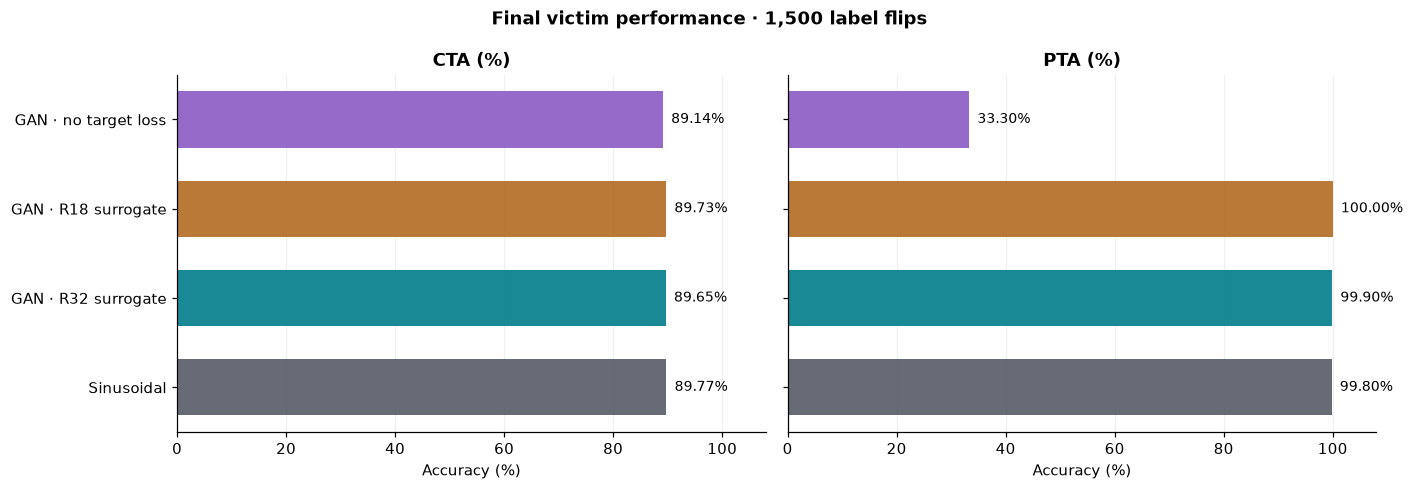

In [2]:
rows = []
for name, info in RUNS.items():
    v = RESULTS[name]
    rows.append({'Method': name, 'CTA (%)': v['cta'][-1] if v else np.nan,
                 'PTA (%)': v['pta'][-1] if v else np.nan,
                 'Flips': BUDGET, 'Evaluations': len(v['cta']) if v else np.nan})
FINAL = pd.DataFrame(rows)
display(FINAL.round(2))
if FINAL['PTA (%)'].notna().any():
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    labels = FINAL['Method'].tolist()
    colors = [PALETTE[n] for n in labels]
    for ax, metric in zip(axes, ('CTA (%)', 'PTA (%)')):
        vals = FINAL[metric].to_numpy(dtype=float)
        bars = ax.barh(range(len(labels)), np.nan_to_num(vals, nan=0), color=colors, alpha=.9, height=.63)
        ax.set_yticks(range(len(labels)), labels)
        ax.invert_yaxis()
        ax.set_xlim(0, 108); ax.set_xlabel('Accuracy (%)'); ax.set_title(metric, fontweight='bold')
        ax.grid(axis='x', alpha=.18); ax.set_axisbelow(True)
        for b, value in zip(bars, vals):
            ax.text((value if np.isfinite(value) else 0) + 1.5, b.get_y() + b.get_height()/2,
                    f'{value:.2f}%' if np.isfinite(value) else 'not run', va='center', fontsize=9)
    fig.suptitle('Final victim performance · 1,500 label flips', fontweight='bold')
    plt.tight_layout(); plt.show()

### 1.1. Difference relative to the sinusoidal baseline

In [3]:
if RESULTS[BASELINE] is not None:
    ref = RESULTS[BASELINE]
    compare_rows = []
    for name, v in RESULTS.items():
        if name == BASELINE or v is None: continue
        compare_rows.append({'Method': name,
            'Δ CTA (pp)': v['cta'][-1] - ref['cta'][-1],
            'Δ PTA (pp)': v['pta'][-1] - ref['pta'][-1]})
    display(pd.DataFrame(compare_rows).round(2))
else:
    print('Sinusoidal baseline user results missing.')

,Method,Δ CTA (pp),Δ PTA (pp)
0,GAN · R32 surrogate,-0.12,0.1
1,GAN · R18 surrogate,-0.04,0.2
2,GAN · no target loss,-0.63,-66.5


## 2. Learning dynamics — CTA and PTA by evaluation epoch

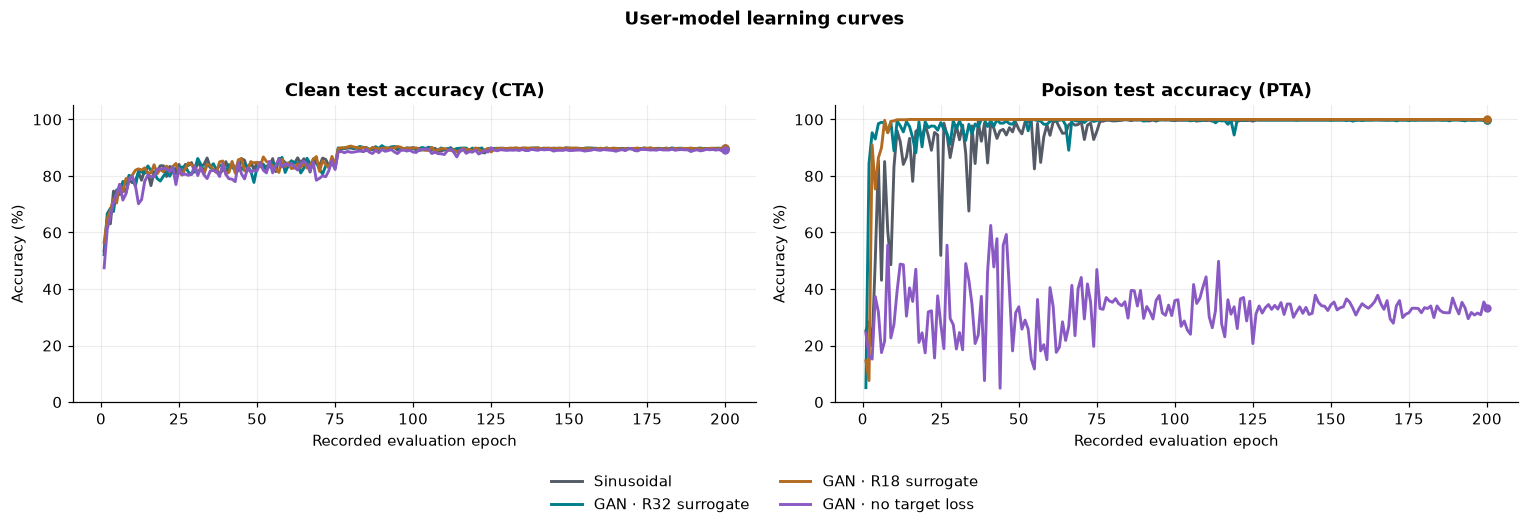

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for name, v in RESULTS.items():
    if v is None: continue
    for ax, key in zip(axes, ('cta', 'pta')):
        epochs = np.arange(1, len(v[key]) + 1)
        ax.plot(epochs, v[key], color=PALETTE[name], label=name, lw=1.9)
        ax.scatter([epochs[-1]], [v[key][-1]], color=PALETTE[name], s=20, zorder=3)
for ax, title in zip(axes, ('Clean test accuracy (CTA)', 'Poison test accuracy (PTA)')):
    ax.set_title(title, fontweight='bold'); ax.set_xlabel('Recorded evaluation epoch')
    ax.set_ylabel('Accuracy (%)'); ax.set_ylim(0, 105); ax.grid(alpha=.22)
handles, labels = axes[1].get_legend_handles_labels()
if handles: fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(.5,-.04), frameon=False)
fig.suptitle('User-model learning curves', fontweight='bold')
plt.tight_layout(rect=(0,.08,1,.94)); plt.show()

## 3. What do the triggers actually look like?

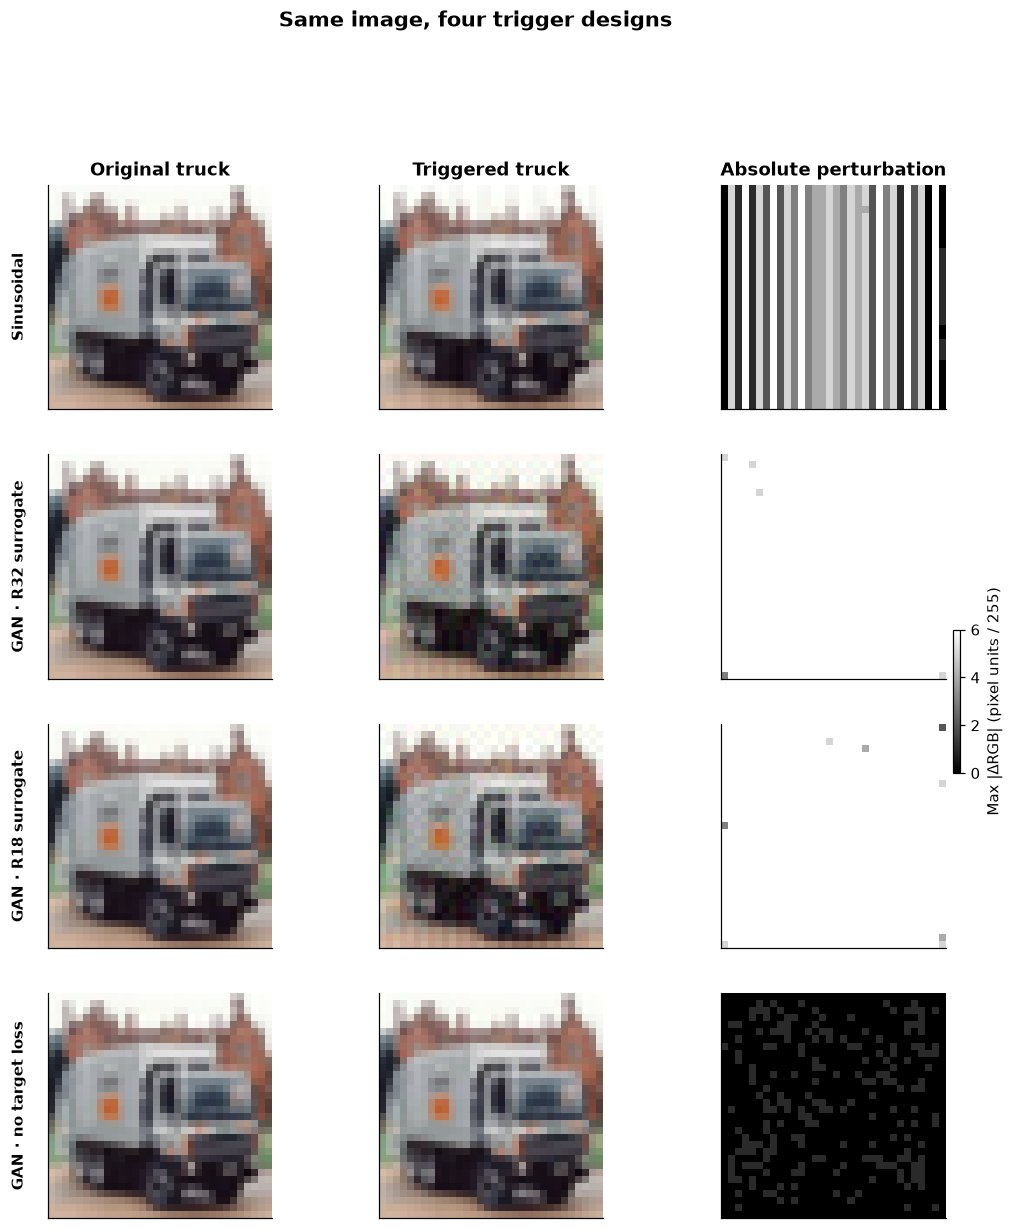

,Method,L∞ applied (pixels / 255),RMS applied (pixels / 255),Mean |Δ| (pixels / 255)
0,Sinusoidal,6.0,4.076,3.587
1,GAN · R32 surrogate,6.0,5.895,5.856
2,GAN · R18 surrogate,6.0,5.845,5.786
3,GAN · no target loss,1.0,0.265,0.070


In [5]:
from torchvision.datasets import CIFAR10
from modules.base_utils.datasets import pick_poisoner

DATA_ROOT = ROOT / 'data/data_cifar10'
cifar = CIFAR10(root=str(DATA_ROOT), train=False, download=False)
truck_idx = next(i for i, y in enumerate(cifar.targets) if y == SOURCE)
clean_img, clean_label = cifar[truck_idx]
clean_arr = np.asarray(clean_img, dtype=np.float32)

IMAGES = {}
trigger_stats = []
for name, info in RUNS.items():
    try:
        poisoned_img = pick_poisoner(info['flag'], 'cifar', TARGET)((clean_img, clean_label))[0]
        image = np.asarray(poisoned_img, dtype=np.float32)
        if image.shape != clean_arr.shape:
            raise ValueError(f'Image shape: {image.shape}')
        diff = image - clean_arr
        IMAGES[name] = {'triggered': image / 255., 'delta': diff}
        trigger_stats.append({'Method': name, 'L∞ applied (pixels / 255)': np.max(np.abs(diff)),
                'RMS applied (pixels / 255)': np.sqrt(np.mean(diff ** 2)),
                'Mean |Δ| (pixels / 255)': np.mean(np.abs(diff))})
    except (FileNotFoundError, OSError) as ex:
        print(f'Skipping {name}: trigger file missing ({ex})')

if IMAGES:
    fig, axes = plt.subplots(len(IMAGES), 3, figsize=(11, 3.05 * len(IMAGES)), squeeze=False)
    for row, (name, v) in enumerate(IMAGES.items()):
        axes[row,0].imshow(clean_img)
        axes[row,1].imshow(v['triggered'])
        im = axes[row,2].imshow(np.abs(v['delta']).max(axis=2), cmap='gray', vmin=0, vmax=6)
        axes[row,0].set_ylabel(name, rotation=90, labelpad=14, fontsize=10, weight='bold')
        for ax in axes[row]: ax.set_xticks([]); ax.set_yticks([])
    for ax, title in zip(axes[0], ('Original truck', 'Triggered truck', 'Absolute perturbation')):
        ax.set_title(title, fontsize=12, fontweight='bold')
    fig.colorbar(im, ax=axes[:,2].tolist(), fraction=.026, pad=.025, label='Max |ΔRGB| (pixel units / 255)')
    fig.suptitle('Same image, four trigger designs', y=1.01, fontsize=14, fontweight='bold')
    plt.show()
    display(pd.DataFrame(trigger_stats).round(3))
else:
    print('No trigger images available; verify the poisoner flags and .npy files.')

### 3.1. The generated perturbations (not just the applied pixel differences)

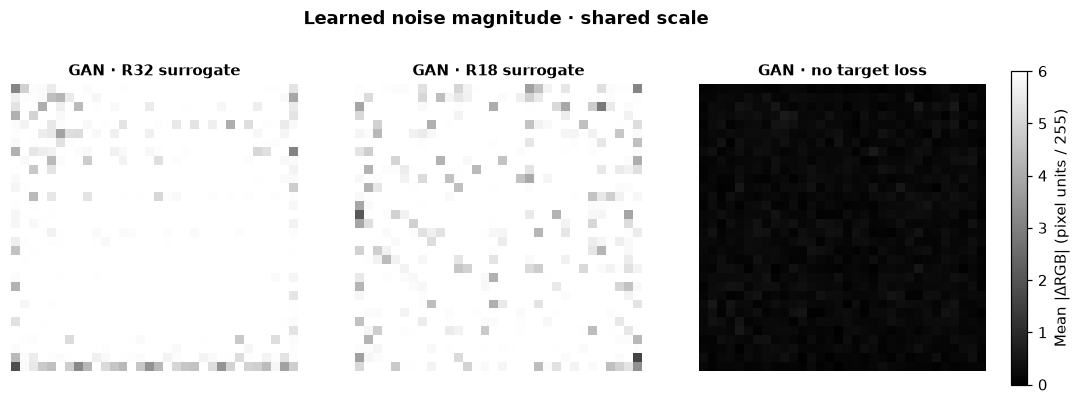

,Method,L∞ (/255),RMS (/255),Mean |noise| (/255)
0,GAN · R32 surrogate,6.000,5.912,5.885
1,GAN · R18 surrogate,6.000,5.873,5.833
2,GAN · no target loss,1.066,0.274,0.214


In [6]:
DELTA_FILES = {
    MAIN_GAN: ROOT / 'noise_generator/universal_delta.npy',
    'GAN · R18 surrogate': ROOT / 'noise_generator/universal_delta_r18.npy',
    'GAN · no target loss': ROOT / 'noise_generator/universal_delta_notarget.npy',
}
arrays = {}; rows = []
for name, path in DELTA_FILES.items():
    if not path.is_file():
        print(f'Missing: {path.relative_to(ROOT)}'); continue
    a = np.load(path).astype(float)
    if a.shape == (3, 32, 32): a = np.transpose(a, (1,2,0))
    if a.shape != (32,32,3):
        print(f'Unexpected noise shape for {name}: {a.shape}'); continue
    arrays[name] = a
    rows.append({'Method': name, 'L∞ (/255)': np.abs(a).max(),
                 'RMS (/255)': np.sqrt((a*a).mean()),
                 'Mean |noise| (/255)': np.abs(a).mean()})
if arrays:
    fig, axes = plt.subplots(1, len(arrays), figsize=(4*len(arrays), 3.7), squeeze=False)
    vmax = max(6., max(np.abs(a).max() for a in arrays.values()))
    for ax, (name,a) in zip(axes[0], arrays.items()):
        im = ax.imshow(np.abs(a).mean(axis=2), cmap='gray', vmin=0, vmax=vmax)
        ax.set_title(name, fontsize=10, fontweight='bold'); ax.axis('off')
    fig.colorbar(im, ax=axes[0].tolist(), fraction=.022, pad=.025,
                 label='Mean |ΔRGB| (pixel units / 255)')
    fig.suptitle('Learned noise magnitude · shared scale', y=1.03, fontweight='bold')
    plt.show()
    display(pd.DataFrame(rows).round(3))

## 4. Zero-flip control: is FLIP label poisoning necessary?

,Method,Flipped labels,CTA (%),PTA (%)
0,Sinusoidal,0,92.61,0.0
1,Sinusoidal,1500,89.77,99.8
2,GAN · R32 surrogate,0,92.63,1.5
3,GAN · R32 surrogate,1500,89.65,99.9


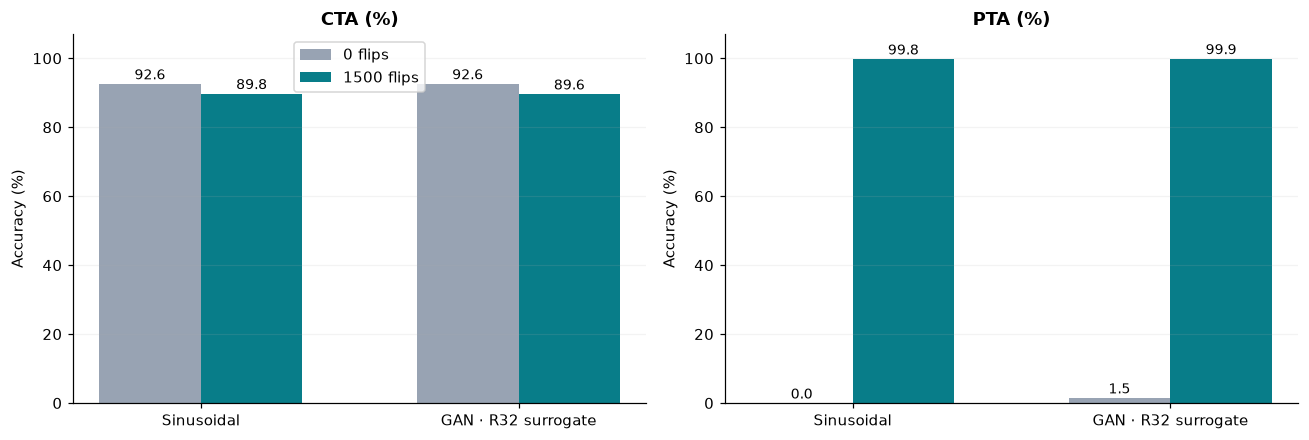

In [7]:
ZERO_CONTROLS = {
    BASELINE: 'zero_flips_sinusoidal',
    MAIN_GAN: 'zero_flips_gan',
}
zero_rows = []
for name, folder in ZERO_CONTROLS.items():
    for flips, run in ((0, folder), (BUDGET, RUNS[name]['user'])):
        data = load_metrics(run)
        if data is None: continue
        zero_rows.append({'Method': name, 'Flipped labels': flips,
                          'CTA (%)': data['cta'][-1], 'PTA (%)': data['pta'][-1]})
ZERO = pd.DataFrame(zero_rows)
if not ZERO.empty:
    display(ZERO.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))
    methods = [k for k in ZERO_CONTROLS if k in ZERO['Method'].values]
    x = np.arange(len(methods)); w=.32
    for ax, metric in zip(axes, ('CTA (%)','PTA (%)')):
        for j, flips in enumerate((0,BUDGET)):
            vals = [ZERO.loc[(ZERO['Method']==name)&(ZERO['Flipped labels']==flips),metric] for name in methods]
            vals = [float(v.iloc[0]) if len(v) else np.nan for v in vals]
            bars = ax.bar(x + (j-.5)*w, np.nan_to_num(vals, nan=0), width=w,
                          color=('#98a3b3' if flips==0 else '#087d89'), label=f'{flips} flips')
            for b, val in zip(bars, vals):
                ax.text(b.get_x()+b.get_width()/2, (val if np.isfinite(val) else 0)+1.3,
                        f'{val:.1f}' if np.isfinite(val) else '—', ha='center', fontsize=9)
        ax.set_xticks(x, methods); ax.set_ylim(0,107); ax.set_ylabel('Accuracy (%)')
        ax.set_title(metric, fontweight='bold'); ax.grid(axis='y',alpha=.15)
    axes[0].legend(); plt.tight_layout(); plt.show()
else: print('Zero-flip files not present.')

## 5. Label-selection analysis — what does FLIP change?

,Method,Actual flips,Flips → deer,Flips from truck,Truck → deer,User labels match
0,Sinusoidal,1500,1106,1290,908,True
1,GAN · R32 surrogate,1500,1068,1260,835,True
2,GAN · R18 surrogate,1500,1076,1016,654,True
3,GAN · no target loss,1500,1500,1500,1500,True


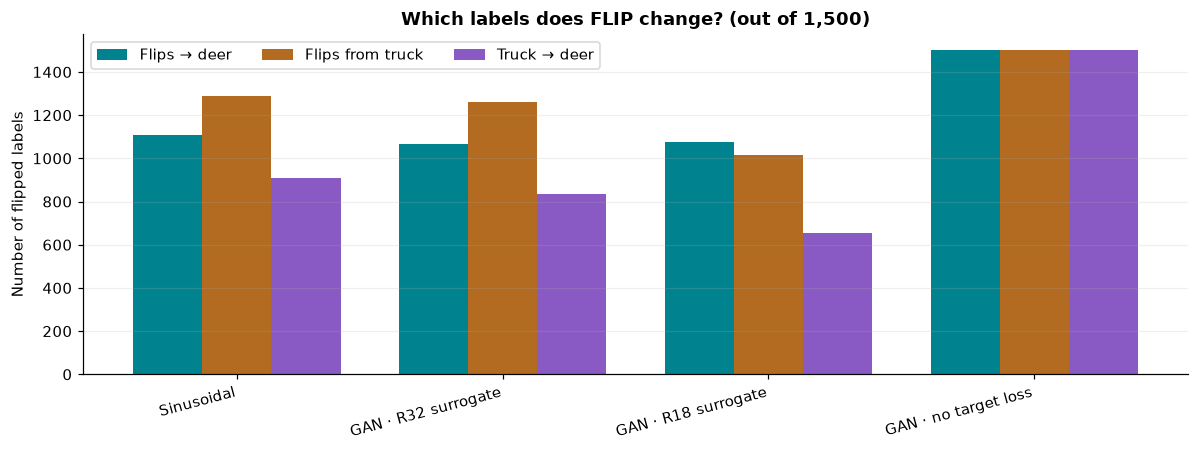

In [8]:
def label_ids(path):
    a = np.load(path)
    if a.ndim == 2: return a.argmax(axis=1)
    if a.ndim == 1: return a.astype(int)
    raise ValueError(f'Unknown label array shape: {a.shape}')

LABEL_SETS = {}; label_rows = []; TRUE_LABELS = {}
for name, info in RUNS.items():
    folder = ROOT / 'experiments' / info['labels']
    true_path, attack_path = folder / 'true.npy', folder / '1500.npy'
    if not (true_path.is_file() and attack_path.is_file()): continue
    true, modified = label_ids(true_path), label_ids(attack_path)
    if true.shape != modified.shape:
        print(f'Skipping {name}: incompatible label shapes'); continue
    idx = np.flatnonzero(true != modified)
    LABEL_SETS[name] = set(idx.tolist()); TRUE_LABELS[name] = true
    row = {'Method': name, 'Actual flips': len(idx),
           'Flips → deer': int(np.sum(modified[idx] == TARGET)),
           'Flips from truck': int(np.sum(true[idx] == SOURCE)),
           'Truck → deer': int(np.sum((true[idx] == SOURCE) & (modified[idx] == TARGET)))}
    label_rows.append(row)
    used_path = ROOT / 'experiments' / info['user'] / 'labels.npy'
    if used_path.is_file():
        row['User labels match'] = bool(np.array_equal(label_ids(used_path), modified))
    else: row['User labels match'] = 'not available'
if label_rows:
    LABELS = pd.DataFrame(label_rows)
    display(LABELS)
    fig, ax = plt.subplots(figsize=(11,4.2))
    classes = LABELS['Method'].tolist(); x=np.arange(len(classes)); w=.26
    for shift, field, color in [(-1,'Flips → deer','#00838f'),(0,'Flips from truck','#b26b21'),(1,'Truck → deer','#8a5ac4')]:
        vals=LABELS[field].to_numpy()
        ax.bar(x+shift*w,vals,width=w,label=field,color=color)
    ax.set_xticks(x,classes,rotation=15,ha='right'); ax.set_ylabel('Number of flipped labels')
    ax.set_title('Which labels does FLIP change? (out of 1,500)',fontweight='bold')
    ax.legend(ncol=3); ax.grid(axis='y',alpha=.2); plt.tight_layout(); plt.show()
else: print('No FLIP label files available.')

### 5.1. Overlap between selected poisoned examples

Identical original label vectors across experiments: True


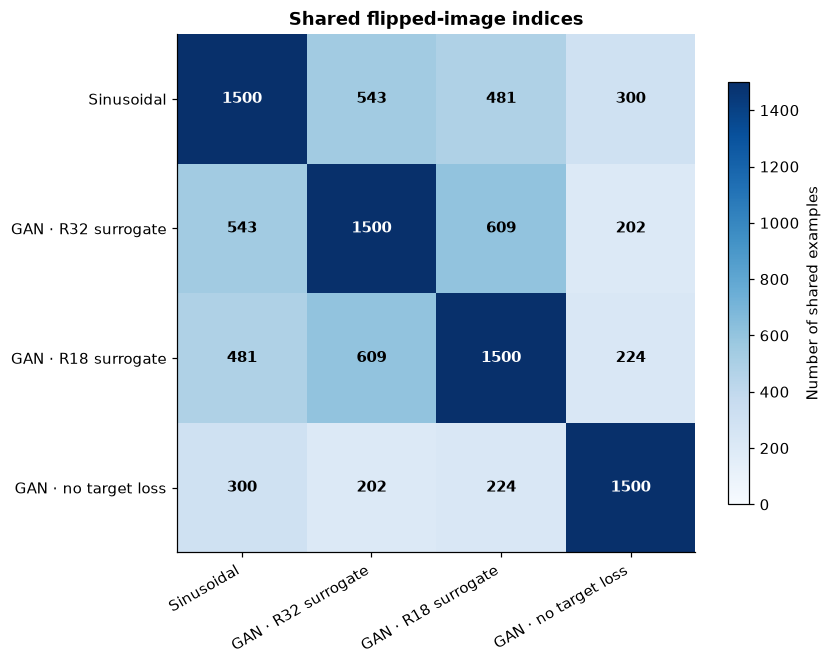

In [9]:
if LABEL_SETS:
    names=list(LABEL_SETS)
    identical_true = all(np.array_equal(TRUE_LABELS[names[0]], TRUE_LABELS[n]) for n in names[1:])
    print('Identical original label vectors across experiments:', identical_true)
    if identical_true:
        M=np.array([[len(LABEL_SETS[a] & LABEL_SETS[b]) for b in names] for a in names])
        fig,ax=plt.subplots(figsize=(7.7,6.4))
        im=ax.imshow(M,cmap='Blues',vmin=0,vmax=max(1500,M.max()))
        ax.set_xticks(range(len(names)),names,rotation=30,ha='right')
        ax.set_yticks(range(len(names)),names)
        for (i,j), val in np.ndenumerate(M):
            ax.text(j,i,str(val),ha='center',va='center',
                    color='white' if val>(M.max()*.55) else 'black',weight='bold')
        ax.set_title('Shared flipped-image indices',fontweight='bold')
        fig.colorbar(im,ax=ax,shrink=.75,label='Number of shared examples')
        plt.tight_layout();plt.show()
    else: print('Different original label ordering; overlap comparison suppressed.')

## 6. GAN ablations: what changes when we modify training?

Surrogate ablation: main GAN uses frozen R32; R18 variant uses frozen R18. Both train a GAN trigger, while FLIP expert and user remain ResNet-32. Target-loss ablation: use the R32 surrogate but set the targeted classification loss weight to zero; the GAN then optimizes only its adversarial term. The final CTA/PTA bars and learning curves above include both ablations wherever their user results are saved.

,Method,CTA (%),PTA (%),Flips,Evaluations
1,GAN · R32 surrogate,89.65,99.9,1500,200
2,GAN · R18 surrogate,89.73,100.0,1500,200
3,GAN · no target loss,89.14,33.3,1500,200


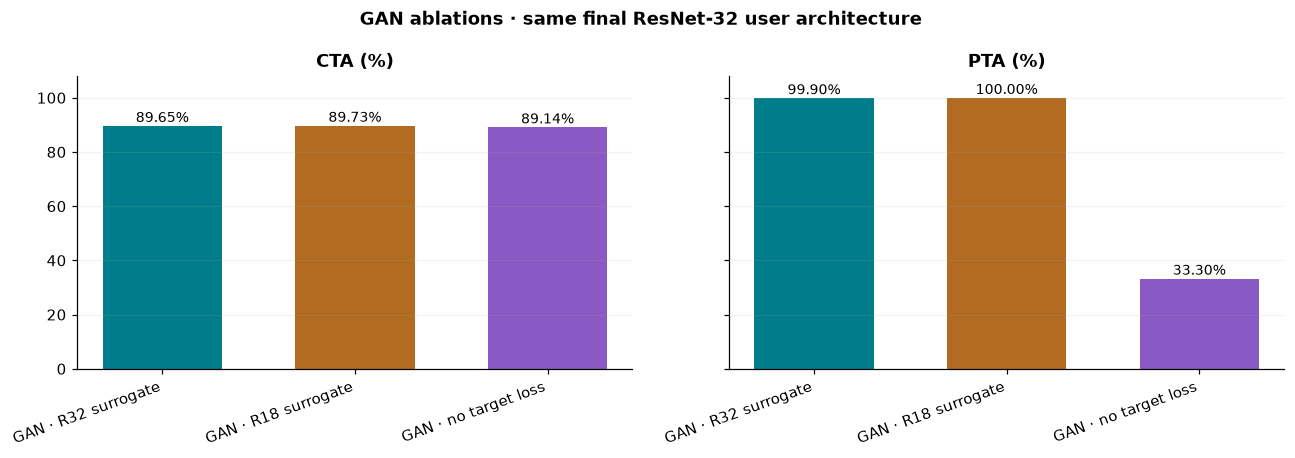

In [10]:
GAN_NAMES = [MAIN_GAN, 'GAN · R18 surrogate', 'GAN · no target loss']
GAN_TABLE = FINAL[FINAL['Method'].isin(GAN_NAMES)].copy()
display(GAN_TABLE.round(2))
if not GAN_TABLE.empty:
    fig, axes=plt.subplots(1,2,figsize=(12,4.2),sharey=True)
    for ax,metric in zip(axes,('CTA (%)','PTA (%)')):
        for i,row in enumerate(GAN_TABLE.itertuples(index=False)):
            name=row[0]; val=float(GAN_TABLE.iloc[i][metric])
            ax.bar(i, val if np.isfinite(val) else 0,color=PALETTE[name],width=.62)
            ax.text(i,(val if np.isfinite(val) else 0)+1.4,
                    f'{val:.2f}%' if np.isfinite(val) else 'not run',ha='center',fontsize=9)
        ax.set_xticks(range(len(GAN_TABLE)),GAN_TABLE['Method'],rotation=20,ha='right')
        ax.set_title(metric,fontweight='bold');ax.set_ylim(0,108);ax.grid(axis='y',alpha=.16)
    fig.suptitle('GAN ablations · same final ResNet-32 user architecture',fontweight='bold')
    plt.tight_layout();plt.show()

## 7. Poisoning-budget experiments (when available)

In [11]:
BUDGETS=[150,300,500,1000,1500]
budget_rows=[]
for name, info in RUNS.items():
    for b in BUDGETS:
        folder=info['user'] if b==1500 else f"{info['user']}_{b}"
        v=load_metrics(folder)
        if v is not None:
            budget_rows.append({'Method':name,'Flips':b,'CTA (%)':v['cta'][-1],'PTA (%)':v['pta'][-1]})
BUDGET_DF=pd.DataFrame(budget_rows)
if not BUDGET_DF.empty:
    display(BUDGET_DF.sort_values(['Method','Flips']).round(2))
    if BUDGET_DF['Flips'].nunique()>1:
        fig,axes=plt.subplots(1,2,figsize=(12.5,4.3))
        for name, group in BUDGET_DF.groupby('Method',sort=False):
            group=group.sort_values('Flips')
            for ax,metric in zip(axes,('CTA (%)','PTA (%)')):
                ax.plot(group['Flips'],group[metric],marker='o',lw=1.8,color=PALETTE[name],label=name)
        for ax,metric in zip(axes,('CTA (%)','PTA (%)')):
            ax.set_title(f'{metric} vs flipped labels',fontweight='bold');ax.set_xlabel('Flipped labels')
            ax.set_ylabel('Accuracy (%)');ax.set_ylim(0,105);ax.grid(alpha=.18)
        axes[1].legend(fontsize=9);plt.tight_layout();plt.show()
    else: print('Only 1,500-flip results exist; lower-budget runs are not yet available.')
else: print('No budget results found.')

,Method,Flips,CTA (%),PTA (%)
2,GAN · R18 surrogate,1500,89.73,100.0
1,GAN · R32 surrogate,1500,89.65,99.9
3,GAN · no target loss,1500,89.14,33.3
0,Sinusoidal,1500,89.77,99.8


Only 1,500-flip results exist; lower-budget runs are not yet available.


## 8. Expert-model reference (separate from user results)
FLIP first trains a backdoored expert to generate poisoned labels. The values below are the expert results previously printed during the relevant experiments; they are not loaded from the final user-model CTA/PTA files and should not be presented as label-only victim performance. Fill in any missing expert value only from its training log.

| Expert trigger | Expert CTA (%) | Expert PTA (%) |
|---|---:|---:|
| Sinusoidal | 84.85 | 99.10 |
| GAN · R32 surrogate | 83.59 | 100.00 |
| GAN · R18 surrogate | 82.32 | 100.00 |
| GAN · no target loss | Not yet verified | Not yet verified |